# Exercício de Regressão Linear Simples

O exercício é em uma análise de um banco de dados `state.x77` do _R_ para predição da variável `Assassinato` (`Murder`). A análise consiste de:
1. Obtenção dos dados;
1. Limpeza, avaliação da qualidade;
1. Avaliação visual das medidas;
1. Comparativo das variáveis (_features_) para identificação da variável independente;
1. Regressão da variável resposta `Assassinato` pela variável independente escolhida;
1. Análise dos resultados;
1. Análise dos resíduos;
1. Relatório sobre os resultados.

## Dados

### Carregamento dos dados brutos

In [1]:
st <- as.data.frame(state.x77[, c("Murder","Population","Illiteracy","Income","Frost","HS Grad")])

### Descrição dos atributos

### Resumo dos dados

In [2]:
summary(st)

     Murder         Population      Illiteracy        Income    
 Min.   : 1.400   Min.   :  365   Min.   :0.500   Min.   :3098  
 1st Qu.: 4.350   1st Qu.: 1080   1st Qu.:0.625   1st Qu.:3993  
 Median : 6.850   Median : 2838   Median :0.950   Median :4519  
 Mean   : 7.378   Mean   : 4246   Mean   :1.170   Mean   :4436  
 3rd Qu.:10.675   3rd Qu.: 4968   3rd Qu.:1.575   3rd Qu.:4814  
 Max.   :15.100   Max.   :21198   Max.   :2.800   Max.   :6315  
     Frost           HS Grad     
 Min.   :  0.00   Min.   :37.80  
 1st Qu.: 66.25   1st Qu.:48.05  
 Median :114.50   Median :53.25  
 Mean   :104.46   Mean   :53.11  
 3rd Qu.:139.75   3rd Qu.:59.15  
 Max.   :188.00   Max.   :67.30  

### Importação do _dataset_

In [3]:
x <- as.data.frame(state.x77)

In [4]:
summary(x)

   Population        Income       Illiteracy       Life Exp    
 Min.   :  365   Min.   :3098   Min.   :0.500   Min.   :67.96  
 1st Qu.: 1080   1st Qu.:3993   1st Qu.:0.625   1st Qu.:70.12  
 Median : 2838   Median :4519   Median :0.950   Median :70.67  
 Mean   : 4246   Mean   :4436   Mean   :1.170   Mean   :70.88  
 3rd Qu.: 4968   3rd Qu.:4814   3rd Qu.:1.575   3rd Qu.:71.89  
 Max.   :21198   Max.   :6315   Max.   :2.800   Max.   :73.60  
     Murder          HS Grad          Frost             Area       
 Min.   : 1.400   Min.   :37.80   Min.   :  0.00   Min.   :  1049  
 1st Qu.: 4.350   1st Qu.:48.05   1st Qu.: 66.25   1st Qu.: 36985  
 Median : 6.850   Median :53.25   Median :114.50   Median : 54277  
 Mean   : 7.378   Mean   :53.11   Mean   :104.46   Mean   : 70736  
 3rd Qu.:10.675   3rd Qu.:59.15   3rd Qu.:139.75   3rd Qu.: 81162  
 Max.   :15.100   Max.   :67.30   Max.   :188.00   Max.   :566432  

### Ajuste dos nomes dos atributos

In [5]:
names(st) <- c("Assassinato", "Populacao", "Analfabetismo", "Renda", 
               "Congelamento", "EnsinoMedio")

### Especificação da região

In [6]:
regiao <- c("Sul","Oeste","Oeste","Sul","Oeste","Oeste","Nordeste","Sul","Sul","Sul",
            "Oeste","Oeste","Meio-Oeste","Meio-Oeste","Meio-Oeste","Meio-Oeste","Sul",
            "Sul","Nordeste","Sul","Nordeste","Meio-Oeste","Meio-Oeste","Sul",
            "Meio-Oeste","Oeste","Meio-Oeste","Oeste","Nordeste","Nordeste","Oeste",
            "Nordeste","Sul","Meio-Oeste","Meio-Oeste","Sul","Oeste","Nordeste",
            "Nordeste","Sul","Meio-Oeste","Sul","Sul","Oeste","Nordeste","Sul","Oeste",
            "Sul","Meio-Oeste","Oeste")
st$Regiao <- factor(regiao)

In [7]:
summary(st)

  Assassinato       Populacao     Analfabetismo       Renda     
 Min.   : 1.400   Min.   :  365   Min.   :0.500   Min.   :3098  
 1st Qu.: 4.350   1st Qu.: 1080   1st Qu.:0.625   1st Qu.:3993  
 Median : 6.850   Median : 2838   Median :0.950   Median :4519  
 Mean   : 7.378   Mean   : 4246   Mean   :1.170   Mean   :4436  
 3rd Qu.:10.675   3rd Qu.: 4968   3rd Qu.:1.575   3rd Qu.:4814  
 Max.   :15.100   Max.   :21198   Max.   :2.800   Max.   :6315  
  Congelamento     EnsinoMedio           Regiao  
 Min.   :  0.00   Min.   :37.80   Meio-Oeste:12  
 1st Qu.: 66.25   1st Qu.:48.05   Nordeste  : 9  
 Median :114.50   Median :53.25   Oeste     :13  
 Mean   :104.46   Mean   :53.11   Sul       :16  
 3rd Qu.:139.75   3rd Qu.:59.15                  
 Max.   :188.00   Max.   :67.30                  

In [8]:
st

,Assassinato,Populacao,Analfabetismo,Renda,Congelamento,EnsinoMedio,Regiao
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
Alabama,15.1,3615,2.1,3624,20,41.3,Sul
Alaska,11.3,365,1.5,6315,152,66.7,Oeste
Arizona,7.8,2212,1.8,4530,15,58.1,Oeste
Arkansas,10.1,2110,1.9,3378,65,39.9,Sul
California,10.3,21198,1.1,5114,20,62.6,Oeste
Colorado,6.8,2541,0.7,4884,166,63.9,Oeste
Connecticut,3.1,3100,1.1,5348,139,56.0,Nordeste
Delaware,6.2,579,0.9,4809,103,54.6,Sul
Florida,10.7,8277,1.3,4815,11,52.6,Sul


## Análise Exploratória

In [9]:
# criando função para dimensionar gráfico no Jupyter
library(repr)
grafdim <- function(x=11,y=9) { options(repr.plot.width=x, repr.plot.height=y) }

O primeiro passo seria uma avaliação visual do comportamento da variáveis, identificar possíveis valores atípicos (_outliers_) e anormalidades de registro ou medição.

### Gráficos de _Boxplot_

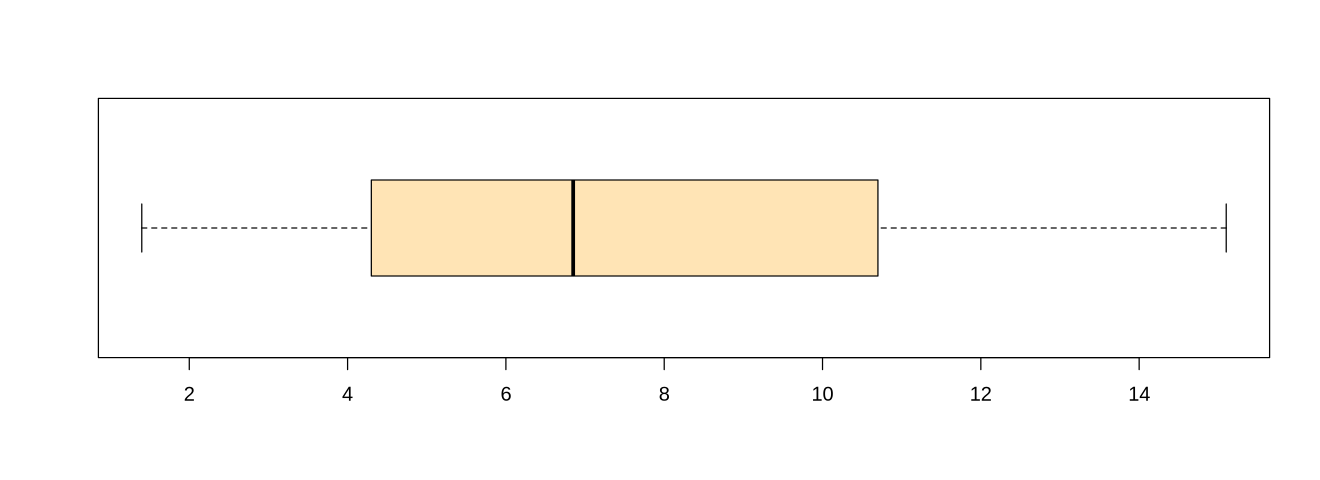

In [10]:
grafdim(11,4)
boxplot(st$Assassinato, horizontal=TRUE, col="moccasin")

In [11]:
ncol(st)

[1] 7

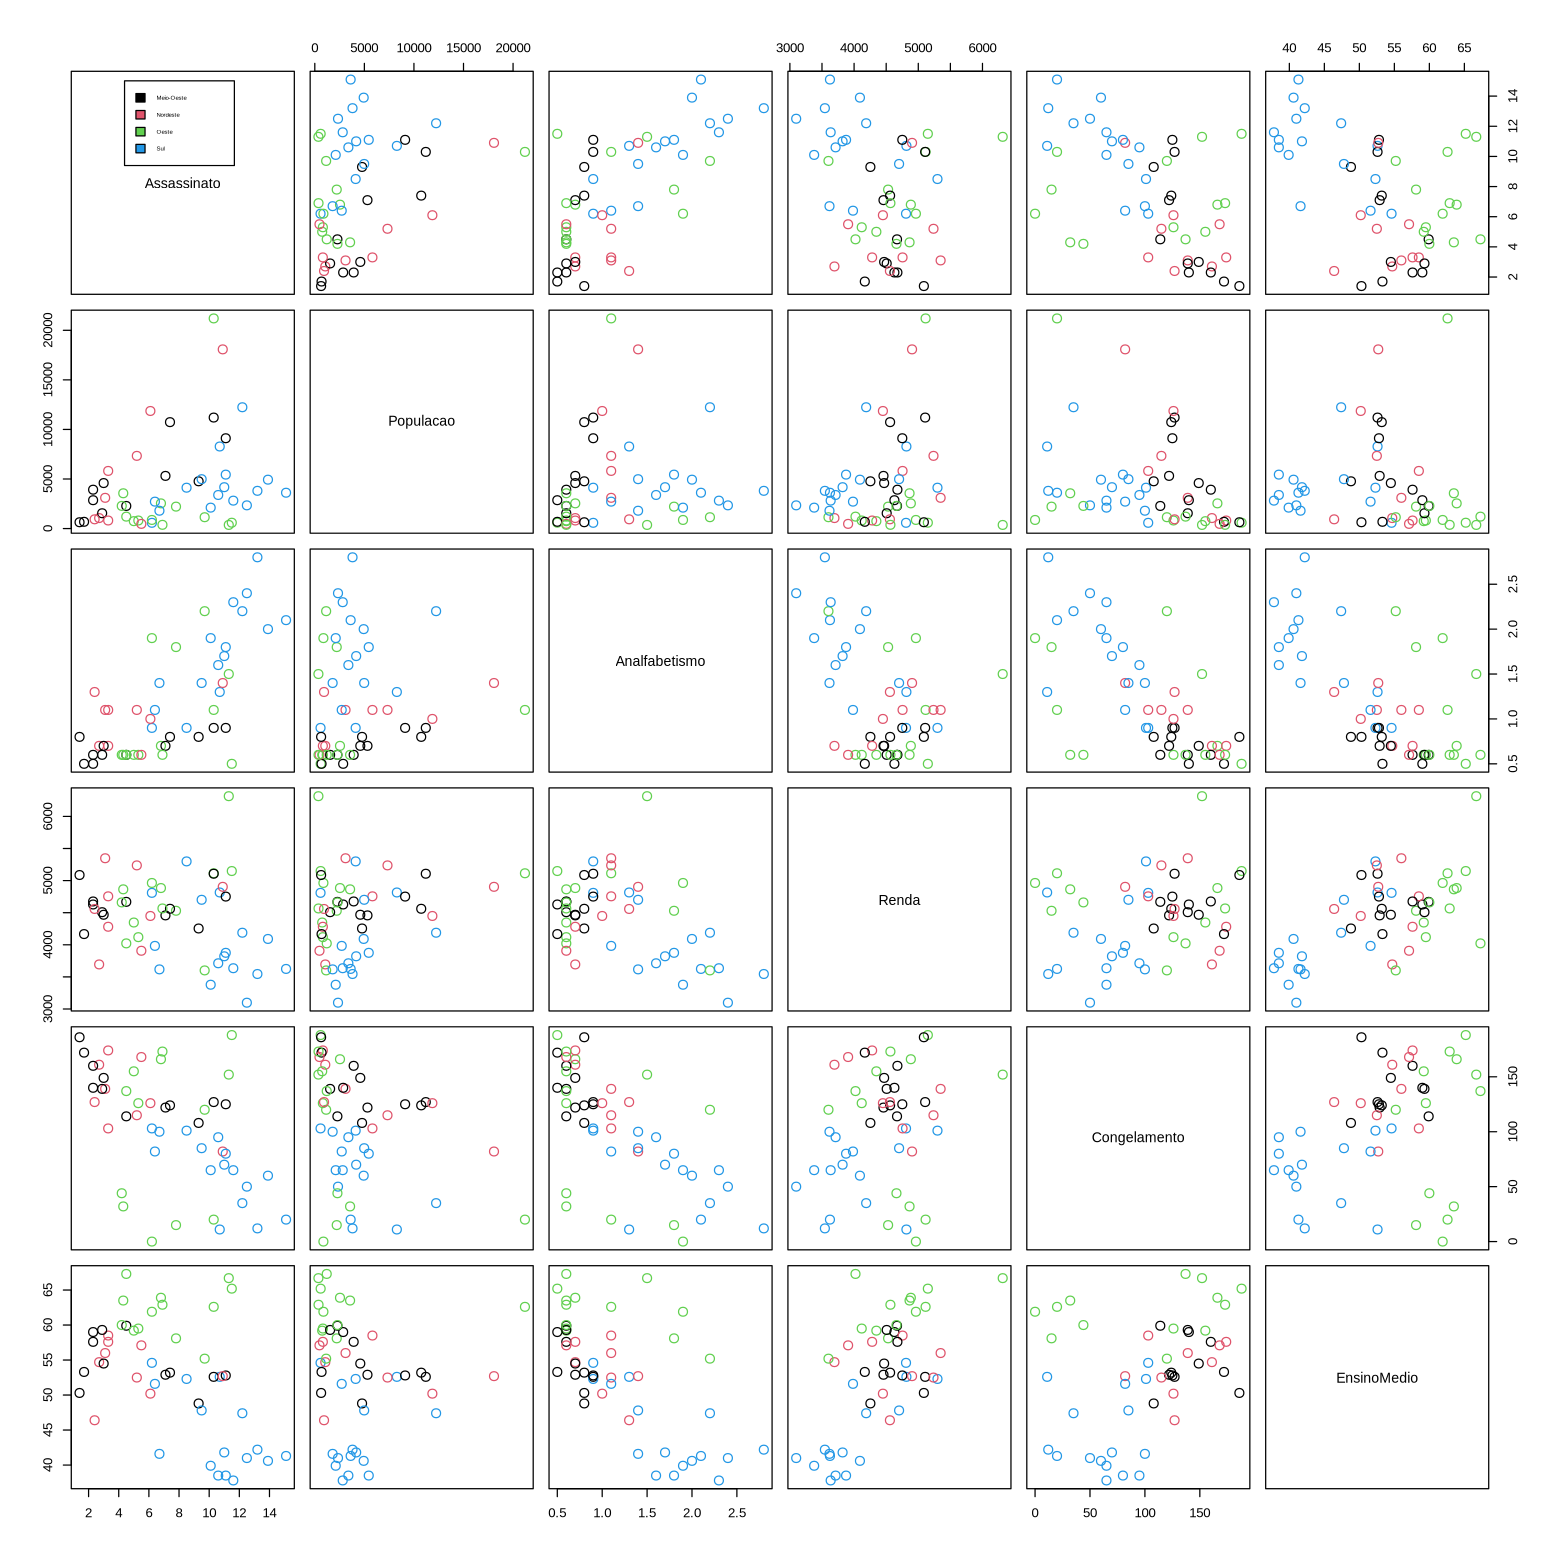

In [12]:
grafdim(13,13)
reg <- c(sort(levels(st$Regiao)))
pairs(st[,1:6], col=st$Regiao, cex=1.5)
par(xpd=TRUE)
legend(0.05,0.98, fill=sort(unique(st$Regiao)), legend=c(sort(levels(st$Regiao))), cex=0.3)

In [13]:
# definindo como calcular o erro absoluto médio:
eam <- function (predito, observado) {
    if (length(predito) == length(observado)) {
        resultado <- sum(abs(predito - observado)) / length(observado)
        return (resultado)
    } else { 
        return (NA) 
    }
}

In [14]:
# definindo como calcular o erro quadrático médio:
eqm <- function (predito, observado) {
    if (length(predito) == length(observado)) {
        diferenca <- predito - observado
        resultado <- sum(diferenca * diferenca) / length(observado)
        return (resultado)
    } else { 
        return (NA) 
    }
}

In [15]:
reg <- lm(formula = Assassinato ~ Analfabetismo, data = st)
summary(reg)


Call:
lm(formula = Assassinato ~ Analfabetismo, data = st)

Residuals:
    Min      1Q  Median      3Q     Max 
-5.5315 -2.0602 -0.2503  1.6916  6.9745 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)     2.3968     0.8184   2.928   0.0052 ** 
Analfabetismo   4.2575     0.6217   6.848 1.26e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.653 on 48 degrees of freedom
Multiple R-squared:  0.4942,	Adjusted R-squared:  0.4836 
F-statistic: 46.89 on 1 and 48 DF,  p-value: 1.258e-08


In [16]:
predito <- fitted(reg)
print(data.frame(st$Assassinato, predito, dif=st$Assassinato-predito))

               st.Assassinato   predito         dif
Alabama                  15.1 11.337435  3.76256523
Alaska                   11.3  8.782961  2.51703927
Arizona                   7.8 10.060198 -2.26019775
Arkansas                 10.1 10.485943 -0.38594342
California               10.3  7.079978  3.22002197
Colorado                  6.8  5.376995  1.42300467
Connecticut               3.1  7.079978 -3.97997803
Delaware                  6.2  6.228487 -0.02848668
Florida                  10.7  7.931469  2.76853062
Georgia                  13.9 10.911689  2.98831090
Hawaii                    6.2 10.485943 -4.28594342
Idaho                     5.3  4.951250  0.34875034
Illinois                 10.3  6.228487  4.07151332
Indiana                   7.1  5.376995  1.72300467
Iowa                      2.3  4.525504 -2.22550398
Kansas                    4.5  4.951250 -0.45124966
Kentucky                 10.6  9.208706  1.39129360
Louisiana                13.2 14.317654 -1.11765449
Maine       

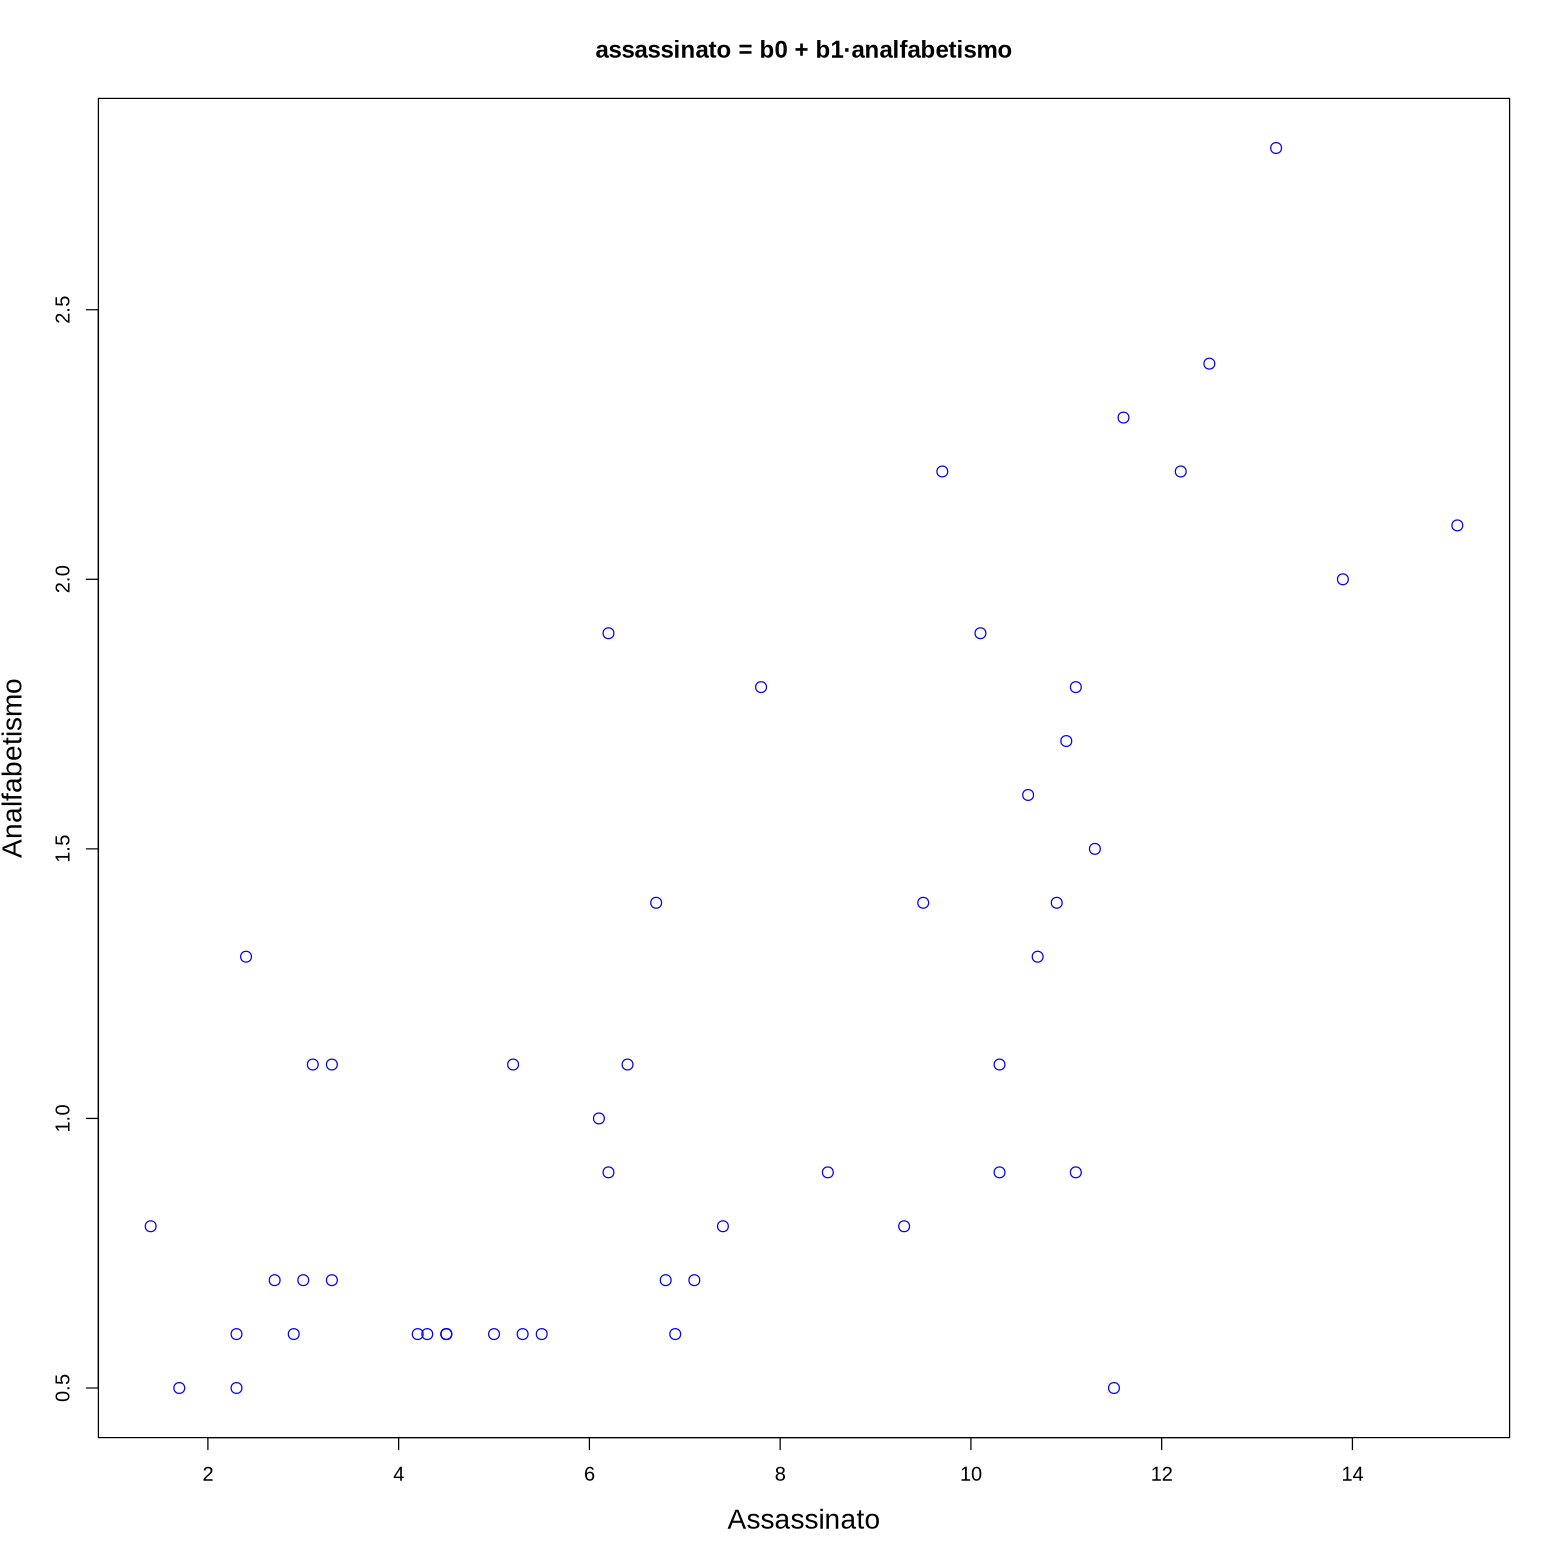

In [17]:
plot(st$Assassinato, st$Analfabetismo,  col="blue", cex=1.2, cex.lab=1.4,
     xlab="Assassinato", ylab="Analfabetismo",
     main="assassinato = b0 + b1·analfabetismo")
abline(reg, col="red")

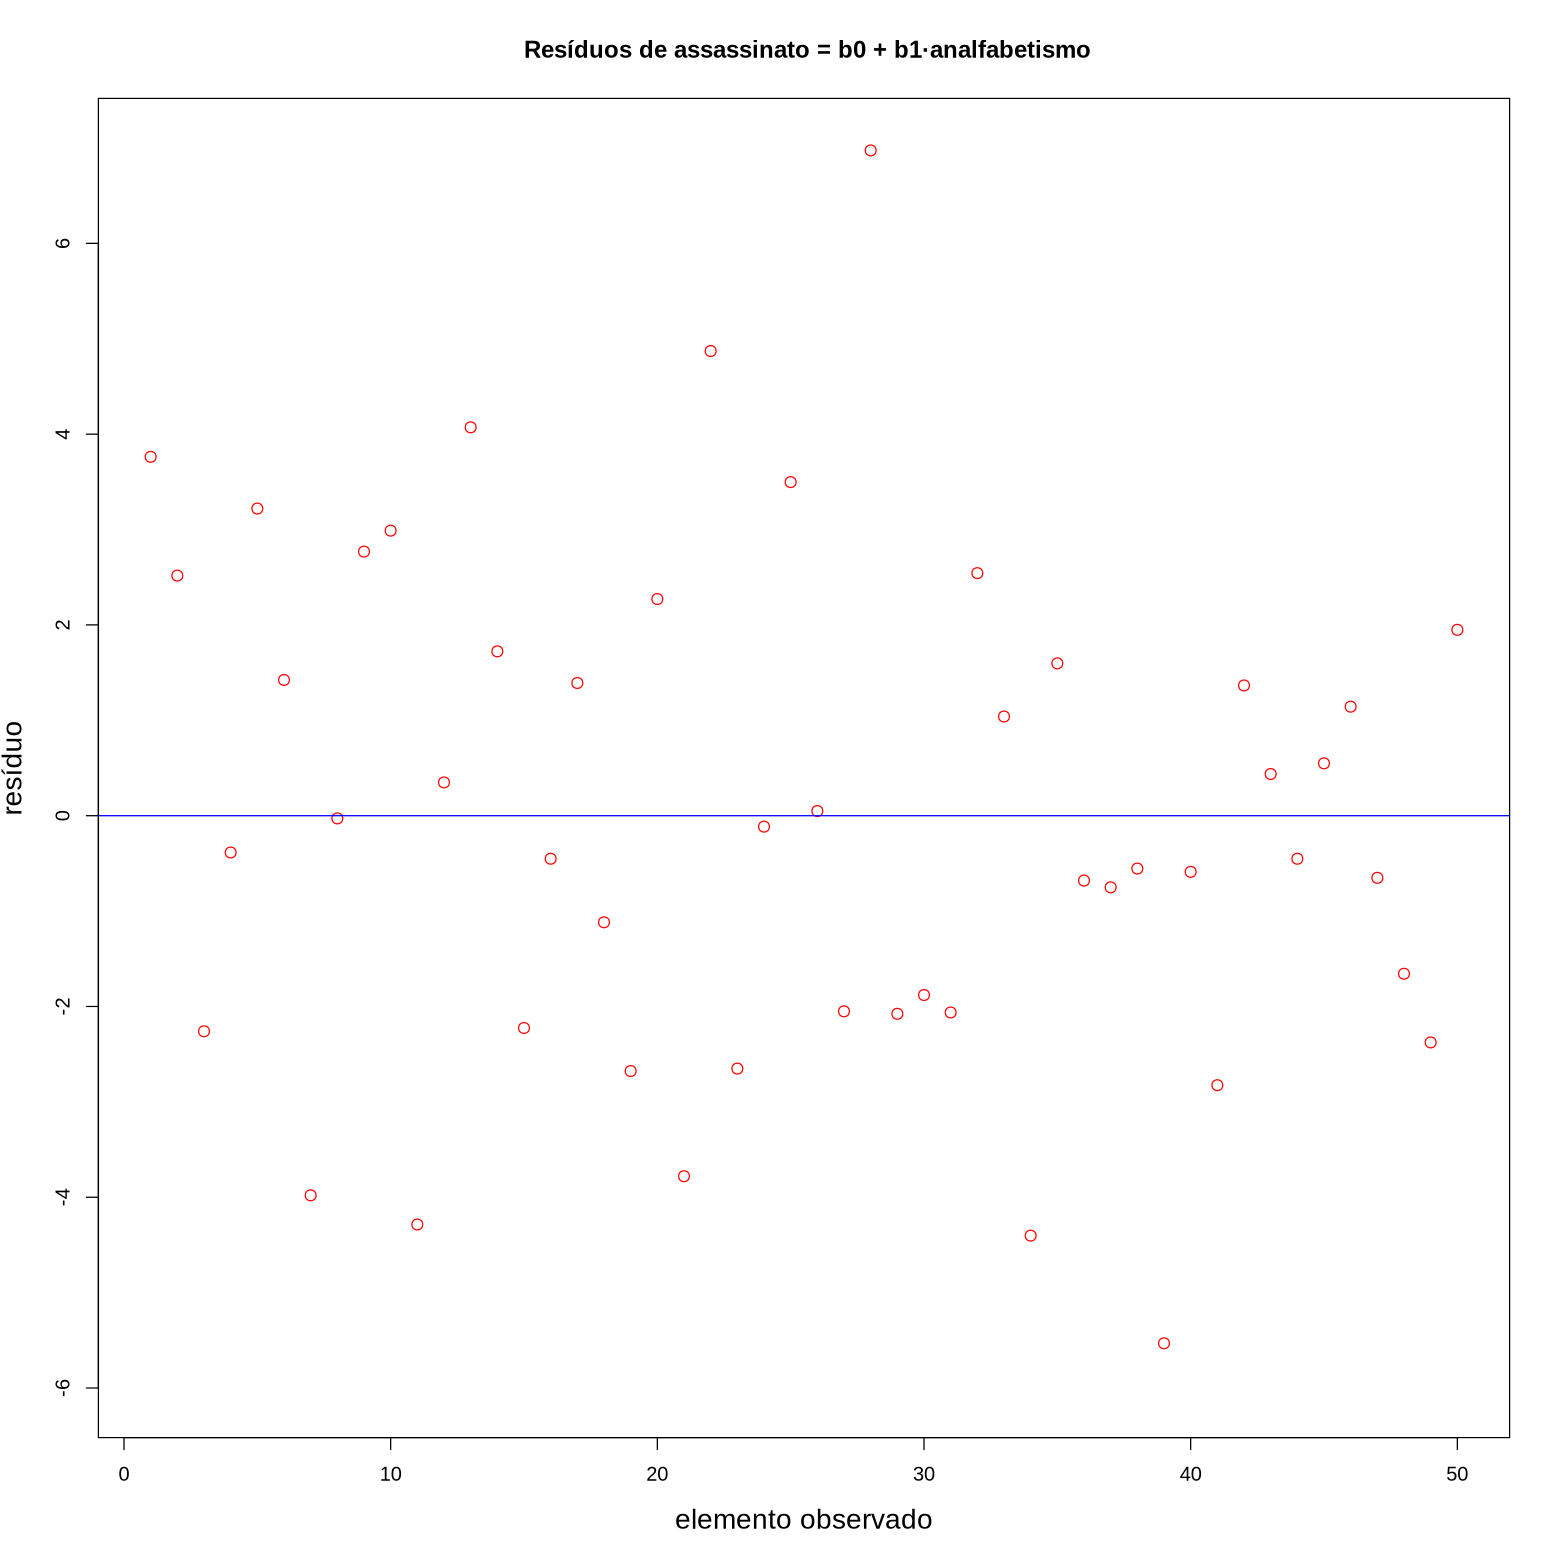

In [18]:
plot(reg$residuals, col="red", cex=1.2, cex.lab=1.4,
     xlab="elemento observado", ylab="resíduo",
     ylim=c(-6,7), main=" Resíduos de assassinato = b0 + b1·analfabetismo")
abline(h=0.0, col="blue")